# Comparación de variables e imputación

**Pregunta predictiva del proyecto:** Dado un préstamo que Lending Club acaba de aprobar, y usando únicamente la información disponible el día del desembolso, ¿qué probabilidad hay de que termine declarado incobrable (`Charged Off`) en lugar de pagarse por completo (`Fully Paid`)?

**Pregunta del experimento:** ¿qué cambia en ROC-AUC y PR-AUC al usar conjuntos distintos de predictoras y al tratar los faltantes con mediana, indicadores o NaN nativo?

Se resumen tres experimentos temporales ya ejecutados. Cada uno usa sus mismos cuatro cortes y preprocesamiento ajustado dentro de cada corte. Los resultados se cargan de `outputs/`; no se reentrenan modelos aquí.

**Precaución:** las 59 predictoras son exploratorias: se definieron con un patrón de cobertura que incluye años posteriores a algunos cortes. Las alternativas de selección dinámica solo miran el entrenamiento de cada corte y por eso son la comparación más limpia para escoger variables.

In [1]:
from pathlib import Path
import sys, os
candidatos_raiz = [Path(os.environ.get("PROYECTO_ML_RAIZ", Path.cwd())).resolve()]
if "__file__" in globals():
    candidatos_raiz.append(Path(__file__).resolve().parent)
raiz_encontrada = next((p for base in candidatos_raiz for p in [base, *base.parents]
                        if (p / "src/config.py").is_file()), None)
if raiz_encontrada is None:
    raise FileNotFoundError("Abra Jupyter dentro del proyecto o defina PROYECTO_ML_RAIZ.")
if str(raiz_encontrada) not in sys.path:
    sys.path.insert(0, str(raiz_encontrada))
from src.rutas import raiz_proyecto
RAIZ = raiz_proyecto(raiz_encontrada)
carpeta = RAIZ


## Reproducción de los experimentos

Cada control ejecuta la implementación conservada en `src/`, con sus semillas, parámetros y cortes originales. Las tablas históricas posteriores permanecen como referencia. Active solo el experimento que quiera regenerar; las salidas nuevas se guardan en `outputs/reproducciones/`, sin reemplazar las métricas históricas. La selección, imputación, indicadores y escalado se ajustan con el entrenamiento de cada corte. Las comparaciones de 59 variables siguen siendo exploratorias.


In [2]:
from src.reproducir import ejecutar_experimento
REGENERAR_VARIABLES = False
if REGENERAR_VARIABLES:
    carpeta_nueva, tablas_nuevas = ejecutar_experimento("variables")
    print("Resultados nuevos:", carpeta_nueva)
    for nombre_tabla, tabla in tablas_nuevas.items():
        display(tabla)


In [3]:
from src.reproducir import ejecutar_experimento
REGENERAR_IMPUTACION = False
if REGENERAR_IMPUTACION:
    carpeta_nueva, tablas_nuevas = ejecutar_experimento("imputacion")
    print("Resultados nuevos:", carpeta_nueva)
    for nombre_tabla, tabla in tablas_nuevas.items():
        display(tabla)


In [4]:
from src.reproducir import ejecutar_experimento
REGENERAR_LINEALES = False
if REGENERAR_LINEALES:
    carpeta_nueva, tablas_nuevas = ejecutar_experimento("lineales")
    print("Resultados nuevos:", carpeta_nueva)
    for nombre_tabla, tabla in tablas_nuevas.items():
        display(tabla)


## Experimento A: selección de variables

In [5]:
from pathlib import Path
import pandas as pd
from IPython.display import display, Image
import matplotlib.pyplot as plt
from IPython.display import display

RAIZ = raiz_proyecto()
if not (RAIZ / "outputs").exists():
    RAIZ = RAIZ.parent
CARPETA = RAIZ / "outputs" / "comparacion_variables_temporal"
resumen_variables = pd.read_csv(CARPETA / "resumen_promedios_y_variabilidad.csv")
por_anio_variables = pd.read_csv(CARPETA / "metricas_por_experimento_y_anio.csv")
display(resumen_variables.round(4))
display(por_anio_variables)


,experimento,tipo_seleccion,ROC_AUC_promedio,ROC_AUC_desviacion,PR_AUC_promedio,PR_AUC_desviacion,variables_min,variables_max,indicadores_promedio
0,A_26_sin_indicadores,solo_entrenamiento,0.7000,0.0195,0.3551,0.0687,26,26,0.00
1,B_26_con_indicadores,solo_entrenamiento,0.6999,0.0195,0.3551,0.0684,26,26,5.25
2,C_59_sin_indicadores,exploratoria,0.7131,0.0203,0.3717,0.0703,59,59,0.00
3,D_59_con_indicadores,exploratoria,0.7133,0.0199,0.3717,0.0702,59,59,38.25
4,E_temporal_sin_indicadores,solo_entrenamiento,0.7033,0.0213,0.3593,0.0740,26,57,0.00
5,F_temporal_con_indicadores,solo_entrenamiento,0.7033,0.0214,0.3595,0.0739,26,57,13.00


,experimento,anio_final_entrenamiento,anio_validacion,filas_entrenamiento,filas_validacion,variables_originales,indicadores_faltantes,variables_numericas,variables_categoricas,faltante_promedio_pct_entrenamiento,faltante_maximo_pct_entrenamiento,tasa_incumplimiento_validacion,ROC_AUC,PR_AUC,segundos_ajuste,tipo_seleccion
0,A_26_sin_indicadores,2012,2013,93153,134804,26,0,20,6,0.163007,3.223729,0.155960,0.674595,0.264998,6.107239,solo_entrenamiento
1,B_26_con_indicadores,2012,2013,93153,134804,26,5,20,6,0.163007,3.223729,0.155960,0.674687,0.265562,4.289158,solo_entrenamiento
2,C_59_sin_indicadores,2012,2013,93153,134804,59,0,53,6,37.303838,73.752858,0.155960,0.686332,0.278649,5.495957,exploratoria
3,D_59_con_indicadores,2012,2013,93153,134804,59,38,53,6,37.303838,73.752858,0.155960,0.687206,0.279381,6.743976,exploratoria
4,E_temporal_sin_indicadores,2012,2013,93153,134804,26,0,20,6,0.163007,3.223729,0.155960,0.674595,0.264998,4.243700,solo_entrenamiento
5,F_temporal_con_indicadores,2012,2013,93153,134804,26,5,20,6,0.163007,3.223729,0.155960,0.674687,0.265562,4.396203,solo_entrenamiento
6,A_26_sin_indicadores,2013,2014,227957,223102,26,0,20,6,0.168520,3.932759,0.184494,0.699852,0.338638,8.948532,solo_entrenamiento
7,B_26_con_indicadores,2013,2014,227957,223102,26,5,20,6,0.168520,3.932759,0.184494,0.699436,0.338188,9.180391,solo_entrenamiento
8,C_59_sin_indicadores,2013,2014,227957,223102,59,0,53,6,15.358234,32.312234,0.184494,0.713511,0.356577,11.913675,exploratoria
9,D_59_con_indicadores,2013,2014,227957,223102,59,38,53,6,15.358234,32.312234,0.184494,0.713158,0.355175,14.137151,exploratoria


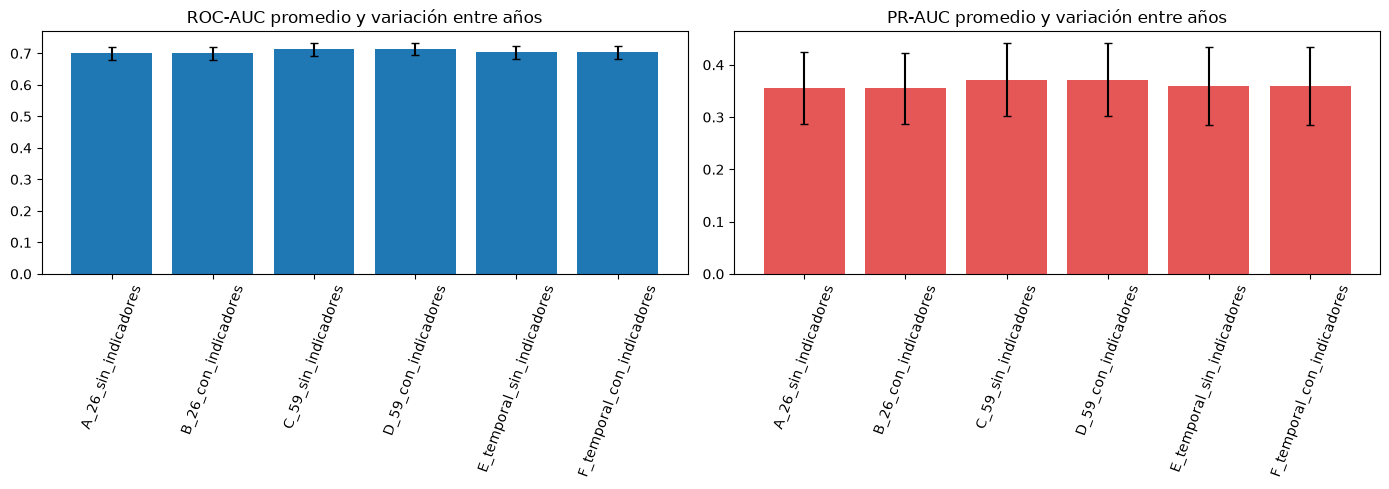

In [6]:
# Comparación descriptiva de promedios por conjunto de variables
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
orden = ['A_26_sin_indicadores', 'B_26_con_indicadores', 'C_59_sin_indicadores',
         'D_59_con_indicadores', 'E_temporal_sin_indicadores', 'F_temporal_con_indicadores']
graf = resumen_variables.set_index('experimento').reindex(orden).dropna(subset=['ROC_AUC_promedio'])
axes[0].bar(graf.index, graf['ROC_AUC_promedio'], yerr=graf['ROC_AUC_desviacion'], capsize=3)
axes[0].set_title('ROC-AUC promedio y variación entre años')
axes[0].tick_params(axis='x', rotation=70)
axes[1].bar(graf.index, graf['PR_AUC_promedio'], yerr=graf['PR_AUC_desviacion'], capsize=3, color='#E45756')
axes[1].set_title('PR-AUC promedio y variación entre años')
axes[1].tick_params(axis='x', rotation=70)
fig.tight_layout()
plt.show()


**Lectura:** la configuración con 59 variables presenta promedios más altos en los resultados registrados, pero está marcada como exploratoria. La selección dinámica por entrenamiento ofrece una estimación menos expuesta a usar información de años futuros, con un promedio distinto y variable según el corte.

## Experimento B: imputación

In [7]:
CARPETA_IMPUTACION = RAIZ / "outputs" / "comparacion_imputacion"
resumen_imputacion = pd.read_csv(CARPETA_IMPUTACION / "resumen_promedios_y_variabilidad.csv")
por_anio_imputacion = pd.read_csv(CARPETA_IMPUTACION / "metricas_por_experimento_y_anio.csv")
display(resumen_imputacion.round(4))
display(por_anio_imputacion)

,seleccion,experimento,metodo,ROC_AUC_promedio,ROC_AUC_desviacion,PR_AUC_promedio,PR_AUC_desviacion,variables_min,variables_max,indicadores_promedio
0,26 fijas,26_fijas_mediana,mediana,0.7000,0.0195,0.3551,0.0687,26,26,0.00
1,26 fijas,26_fijas_mediana_indicadores,mediana_indicadores,0.6999,0.0195,0.3551,0.0684,26,26,5.25
2,26 fijas,26_fijas_nan_nativo,nan_nativo,0.7000,0.0195,0.3549,0.0684,26,26,0.00
3,solo entrenamiento,seleccion_temporal_mediana,mediana,0.7033,0.0213,0.3593,0.0740,26,57,0.00
4,solo entrenamiento,seleccion_temporal_mediana_indicadores,mediana_indicadores,0.7033,0.0214,0.3595,0.0739,26,57,13.00
5,solo entrenamiento,seleccion_temporal_nan_nativo,nan_nativo,0.7034,0.0215,0.3593,0.0739,26,57,0.00


,experimento,metodo,anio_final_entrenamiento,anio_validacion,filas_entrenamiento,filas_validacion,variables_originales,indicadores_faltantes,variables_numericas,variables_categoricas,faltantes_numericos_entrenamiento,faltantes_numericos_validacion,faltante_maximo_pct_entrenamiento,tasa_incumplimiento_validacion,ROC_AUC,PR_AUC,segundos_ajuste,NaN_entrenamiento_conservados,NaN_validacion_conservados,seleccion
0,26_fijas_mediana,mediana,2012,2013,93153,134804,26,0,20,6,945,78,3.223729,0.155960,0.674595,0.264998,5.279320,0,0,26 fijas
1,26_fijas_mediana_indicadores,mediana_indicadores,2012,2013,93153,134804,26,5,20,6,945,78,3.223729,0.155960,0.674687,0.265562,3.987990,0,0,26 fijas
2,26_fijas_nan_nativo,nan_nativo,2012,2013,93153,134804,26,0,20,6,945,78,3.223729,0.155960,0.674567,0.265377,3.881929,945,78,26 fijas
3,seleccion_temporal_mediana,mediana,2012,2013,93153,134804,26,0,20,6,945,78,3.223729,0.155960,0.674595,0.264998,3.853423,0,0,solo entrenamiento
4,seleccion_temporal_mediana_indicadores,mediana_indicadores,2012,2013,93153,134804,26,5,20,6,945,78,3.223729,0.155960,0.674687,0.265562,3.947355,0,0,solo entrenamiento
5,seleccion_temporal_nan_nativo,nan_nativo,2012,2013,93153,134804,26,0,20,6,945,78,3.223729,0.155960,0.674567,0.265377,3.850671,945,78,solo entrenamiento
6,26_fijas_mediana,mediana,2013,2014,227957,223102,26,0,20,6,1023,115,3.932759,0.184494,0.699852,0.338638,7.147029,0,0,26 fijas
7,26_fijas_mediana_indicadores,mediana_indicadores,2013,2014,227957,223102,26,5,20,6,1023,115,3.932759,0.184494,0.699436,0.338188,7.351608,0,0,26 fijas
8,26_fijas_nan_nativo,nan_nativo,2013,2014,227957,223102,26,0,20,6,1023,115,3.932759,0.184494,0.699855,0.338282,7.192560,1023,115,26 fijas
9,seleccion_temporal_mediana,mediana,2013,2014,227957,223102,26,0,20,6,1023,115,3.932759,0.184494,0.699852,0.338638,7.068723,0,0,solo entrenamiento


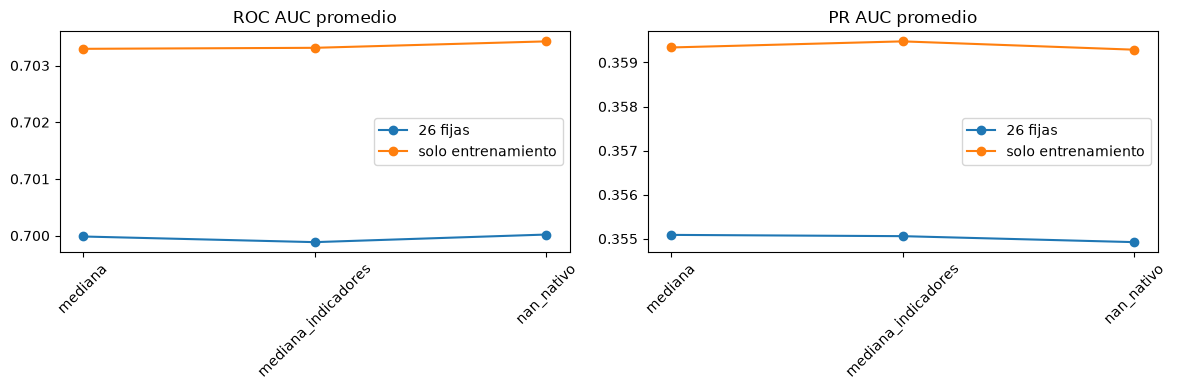

In [8]:
# Diferencias pequeñas entre tratamientos: mostrar el promedio con variación anual.
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for metrica, ax in [('ROC_AUC_promedio', axes[0]), ('PR_AUC_promedio', axes[1])]:
    for seleccion in resumen_imputacion['seleccion'].unique():
        parte = resumen_imputacion[resumen_imputacion['seleccion'] == seleccion]
        ax.plot(parte['metodo'], parte[metrica], marker='o', label=seleccion)
    ax.set_title(metrica.replace('_', ' '))
    ax.tick_params(axis='x', rotation=45)
    ax.legend()
fig.tight_layout()
plt.show()


**Lectura:** en estos resultados las diferencias entre mediana sola, mediana con indicadores y NaN nativo son pequeñas. No se debe afirmar que los indicadores mejoren de forma consistente sin una diferencia estable entre cortes.

## Experimento C: modelos lineales y boosting

In [9]:
CARPETA_LINEALES = RAIZ / "outputs" / "comparacion_lineales"
resumen_lineales = pd.read_csv(CARPETA_LINEALES / "resumen_promedios_y_variabilidad.csv")
por_anio_lineales = pd.read_csv(CARPETA_LINEALES / "metricas_por_configuracion_y_anio.csv")
display(resumen_lineales.round(4))
display(por_anio_lineales)

,conjunto_variables,tipo_seleccion,modelo,tratamiento,ROC_AUC_promedio,ROC_AUC_desviacion,PR_AUC_promedio,PR_AUC_desviacion,variables_min,variables_max,indicadores_promedio,cortes_convergencia
0,26_fijas,solo_entrenamiento,regresion_logistica,Mediana,0.6927,0.0181,0.3484,0.0644,26,26,0.00,0
1,26_fijas,solo_entrenamiento,regresion_logistica,Mediana + indicadores,0.6927,0.0181,0.3484,0.0644,26,26,5.25,0
2,26_fijas,solo_entrenamiento,svm_lineal,Mediana,0.6926,0.0185,0.3477,0.0644,26,26,0.00,0
3,26_fijas,solo_entrenamiento,svm_lineal,Mediana + indicadores,0.6925,0.0186,0.3477,0.0643,26,26,5.25,0
4,59_exploratorias,exploratoria,regresion_logistica,Mediana,0.7054,0.0181,0.3624,0.0652,59,59,0.00,0
5,59_exploratorias,exploratoria,regresion_logistica,Mediana + indicadores,0.7055,0.0182,0.3622,0.0655,59,59,38.25,0
6,59_exploratorias,exploratoria,svm_lineal,Mediana,0.7052,0.0186,0.3615,0.0655,59,59,0.00,0
7,59_exploratorias,exploratoria,svm_lineal,Mediana + indicadores,0.7053,0.0187,0.3611,0.0658,59,59,38.25,0
8,seleccion_temporal,solo_entrenamiento,regresion_logistica,Mediana,0.6962,0.0193,0.3522,0.0689,26,57,0.00,0
9,seleccion_temporal,solo_entrenamiento,regresion_logistica,Mediana + indicadores,0.6962,0.0193,0.3521,0.0688,26,57,13.00,0


,experimento,modelo,anio_final_entrenamiento,anio_validacion,filas_entrenamiento,filas_validacion,variables_originales,indicadores_faltantes,variables_numericas,variables_categoricas,faltante_maximo_pct_entrenamiento,ROC_AUC,PR_AUC,segundos_ajuste,advertencia_convergencia,conjunto_variables,tipo_seleccion,tratamiento
0,26_fijas_regresion_logistica_mediana,regresion_logistica,2012,2013,93153,134804,26,0,20,6,3.223729,0.669694,0.263071,5.485661,False,26_fijas,solo_entrenamiento,Mediana
1,26_fijas_regresion_logistica_mediana_indicadores,regresion_logistica,2012,2013,93153,134804,26,5,20,6,3.223729,0.669529,0.262834,5.142989,False,26_fijas,solo_entrenamiento,Mediana + indicadores
2,26_fijas_svm_lineal_mediana,svm_lineal,2012,2013,93153,134804,26,0,20,6,3.223729,0.669406,0.262263,2.293378,False,26_fijas,solo_entrenamiento,Mediana
3,26_fijas_svm_lineal_mediana_indicadores,svm_lineal,2012,2013,93153,134804,26,5,20,6,3.223729,0.669266,0.262150,2.511295,False,26_fijas,solo_entrenamiento,Mediana + indicadores
4,59_exploratorias_regresion_logistica_mediana,regresion_logistica,2012,2013,93153,134804,59,0,53,6,73.752858,0.682743,0.276068,18.235806,False,59_exploratorias,exploratoria,Mediana
5,59_exploratorias_regresion_logistica_mediana_i...,regresion_logistica,2012,2013,93153,134804,59,38,53,6,73.752858,0.682696,0.275712,21.839279,False,59_exploratorias,exploratoria,Mediana + indicadores
6,59_exploratorias_svm_lineal_mediana,svm_lineal,2012,2013,93153,134804,59,0,53,6,73.752858,0.681880,0.274419,7.979319,False,59_exploratorias,exploratoria,Mediana
7,59_exploratorias_svm_lineal_mediana_indicadores,svm_lineal,2012,2013,93153,134804,59,38,53,6,73.752858,0.681898,0.274128,12.375059,False,59_exploratorias,exploratoria,Mediana + indicadores
8,seleccion_temporal_regresion_logistica_mediana,regresion_logistica,2012,2013,93153,134804,26,0,20,6,3.223729,0.669694,0.263071,5.656178,False,seleccion_temporal,solo_entrenamiento,Mediana
9,seleccion_temporal_regresion_logistica_mediana...,regresion_logistica,2012,2013,93153,134804,26,5,20,6,3.223729,0.669529,0.262834,5.060591,False,seleccion_temporal,solo_entrenamiento,Mediana + indicadores


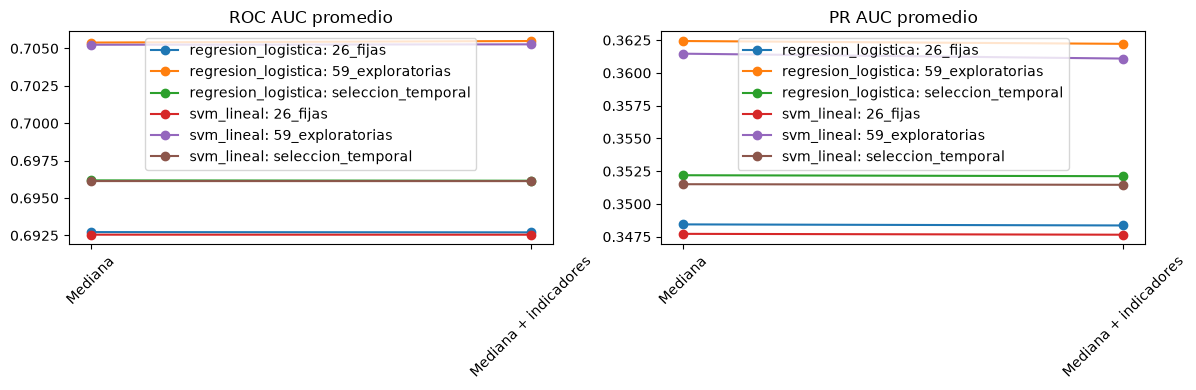

In [10]:
# Comparar modelos lineales en los tratamientos registrados.
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for metrica, ax in [('ROC_AUC_promedio', axes[0]), ('PR_AUC_promedio', axes[1])]:
    for (modelo, conjunto), parte in resumen_lineales.groupby(['modelo', 'conjunto_variables']):
        ax.plot(parte['tratamiento'], parte[metrica], marker='o', label=f"{modelo}: {conjunto}")
    ax.set_title(metrica.replace('_', ' '))
    ax.tick_params(axis='x', rotation=45)
    ax.legend()
fig.tight_layout()
plt.show()


## Conclusiones y límites

- En la comparación temporal, 59 variables es una alternativa exploratoria; no debe confundirse con una selección hecha sin mirar cobertura futura.
- La selección dinámica muestra cómo varía la cantidad de variables disponibles por corte; no impone un conteo fijo.
- Los indicadores de faltantes no mostraron una ventaja importante y uniforme frente a mediana sola en estas pruebas.
- Esta consolidación presenta los registros guardados. Para repetir el ajuste completo, consultar los notebooks originales indicados en `README.md`.